In [ ]:
# 1. Upload dataset dari Google Colab
from google.colab import files
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor, plot_importance
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# 1. Upload dataset dari Google Colab
from google.colab import files
uploaded = files.upload()

Saving internet_adoption_indonesia_only.csv to internet_adoption_indonesia_only.csv


In [ ]:
# 3. Load dataset
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

# 4. Tampilkan informasi awal
print("Info dataset:")
print(df.info())
print("\nStatistik deskriptif:")
print(df.describe())
print("\nContoh data:")
print(df.head())

Info dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5625 entries, 0 to 5624
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Country                     5625 non-null   object 
 1   Date                        5625 non-null   object 
 2   Internet_Penetration (%)    5625 non-null   float64
 3   Broadband_Speed (Mbps)      5625 non-null   float64
 4   GDP_Per_Capita (USD)        5625 non-null   float64
 5   Education_Level (%)         5625 non-null   float64
 6   Mobile_Data_Usage (GB)      5625 non-null   float64
 7   Digital_Investment (M USD)  5625 non-null   float64
 8   Digital_Literacy (%)        5625 non-null   float64
 9   X_Sentiment_Score           5625 non-null   float64
 10  5G_Rollout                  5625 non-null   int64  
 11  Urban_Rural                 5625 non-null   object 
 12  Latitude                    5625 non-null   float64
 13  Longitude          

In [ ]:
# 5. Tentukan target (ubah sesuai kolom target yang benar)
target = 'Internet_Penetration (%)'  # Ganti kalau nama target beda

In [ ]:
# 6. Pisahkan fitur dan target
X = df.drop(columns=[target, 'Date'], errors='ignore')  # Drop 'Date' jika ada
y = df[target]

In [ ]:
# i. Imputasi Missing Value (numerik) dengan median
num_cols = X.select_dtypes(include=np.number).columns
X[num_cols] = X[num_cols].fillna(X[num_cols].median())

# ii. Deteksi & treatment outlier dengan IQR
for col in num_cols:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Cap outliers
    X[col] = np.where(X[col] < lower_bound, lower_bound,
                      np.where(X[col] > upper_bound, upper_bound, X[col]))

# iii. Normalisasi numerik dengan StandardScaler
scaler = StandardScaler()
X[num_cols] = scaler.fit_transform(X[num_cols])

# iv. One-hot encoding untuk fitur kategorikal
categorical_cols = X.select_dtypes(include='object').columns.tolist()
print("\nFitur kategorikal yang akan diencode:", categorical_cols)
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)


Fitur kategorikal yang akan diencode: ['Country', 'Urban_Rural']


In [ ]:
# 8. Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# 9. Inisialisasi dan training model XGBoost
model = XGBRegressor(n_estimators=100, learning_rate=0.2, max_depth=5, random_state=42)
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.2, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=5, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=100, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [ ]:
# 10. Prediksi dan evaluasi
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\n📊 Mean Squared Error (MSE): {mse:.2f}")
print(f"📈 R² Score: {r2:.3f}")


📊 Mean Squared Error (MSE): 1.32
📈 R² Score: 0.998


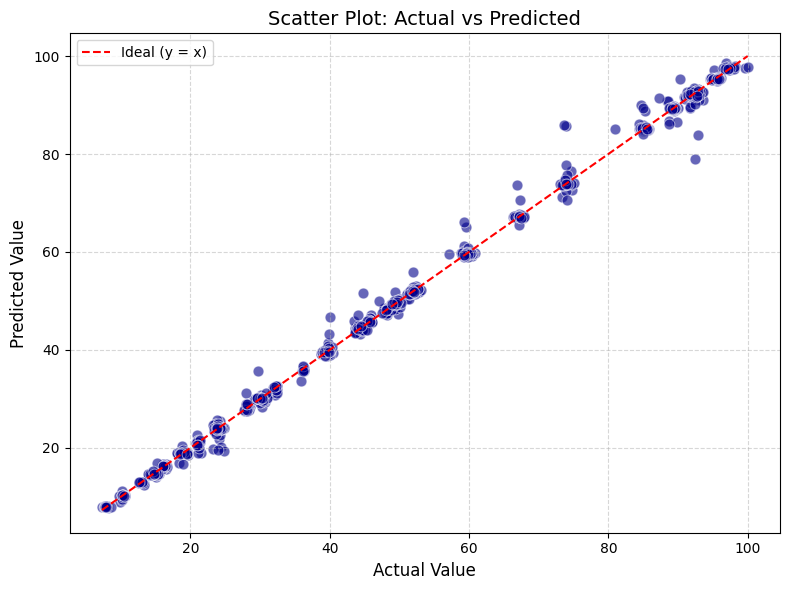

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, color='darkblue', alpha=0.6, s=60)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Ideal (y = x)")
plt.xlabel("Actual Value", fontsize=12)
plt.ylabel("Predicted Value", fontsize=12)
plt.title("Scatter Plot: Actual vs Predicted", fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

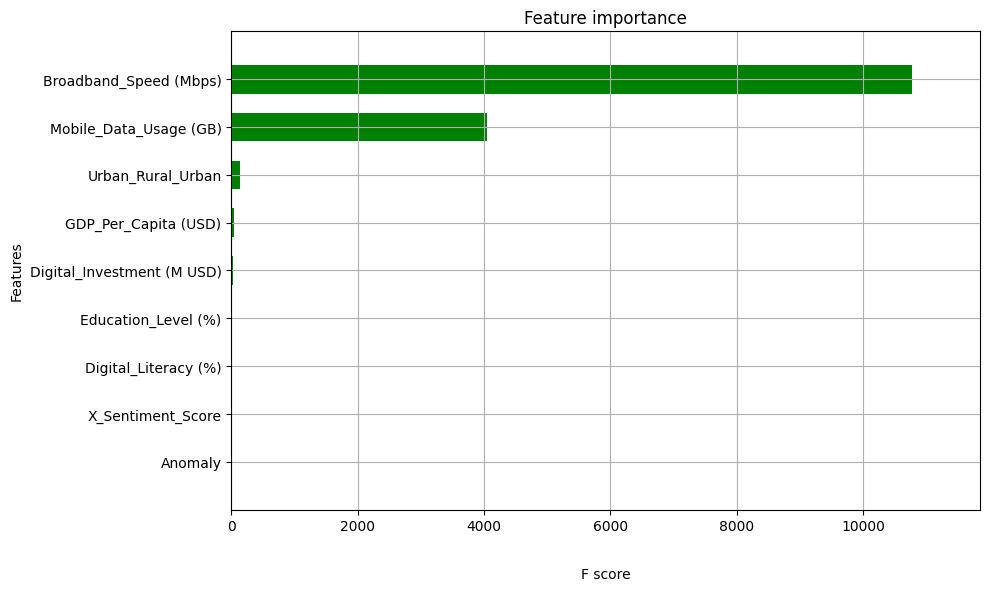

In [ ]:
import matplotlib.pyplot as plt
from xgboost import plot_importance

# Buat figure dan axis manual
fig, ax = plt.subplots(figsize=(10, 6))

# Plot importance ke axis yang sudah dibuat
plot_importance(
    model,
    importance_type='gain',
    max_num_features=10,
    height=0.6,
    color='green',
    show_values=False,
    ax=ax
)

# Rapikan label sumbu X
ax.set_xlabel("F score", labelpad=20)  # tambahkan jarak dari angka ke label

# Tambahan: bisa naikkan posisi xlabel manual jika masih kurang
ax.xaxis.set_label_coords(0.5, -0.12)  # (horizontal_pos, vertical_pos)

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(model, X, y, cv=5, scoring='r2')
print(f"R² Cross-Validation (5-Fold): {cv_scores.mean():.3f}")


R² Cross-Validation (5-Fold): 0.799


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2]
}

grid = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='r2')
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV score:", grid.best_score_)


Best parameters: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 100}
Best CV score: 0.9986359631544228



=== Random Forest Regressor ===
📊 Mean Squared Error (MSE): 1.71
📈 R² Score: 0.998


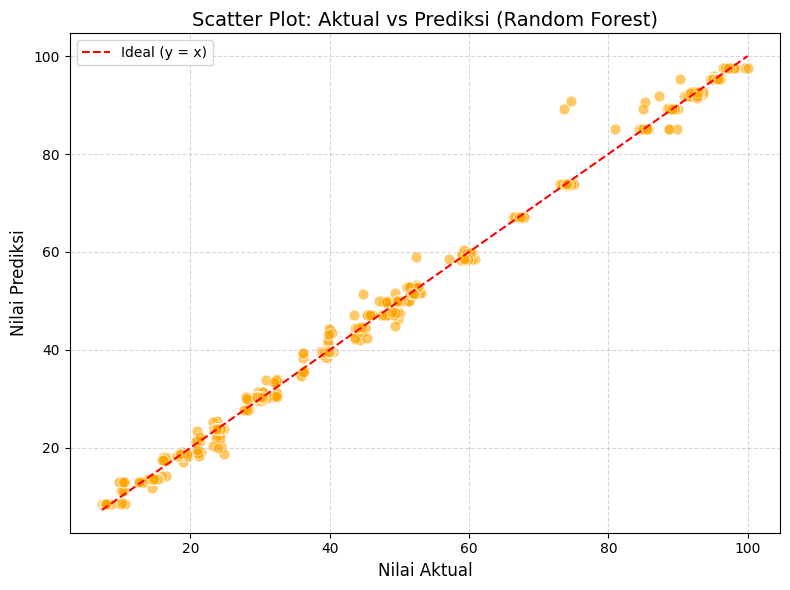

In [ ]:
# =======================
# Analisis dengan Random Forest
# =======================
from sklearn.ensemble import RandomForestRegressor

# 1. Inisialisasi dan pelatihan model Random Forest
rf_model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train, y_train)

# 2. Prediksi dan evaluasi model Random Forest
rf_pred = rf_model.predict(X_test)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("\n=== Random Forest Regressor ===")
print(f"📊 Mean Squared Error (MSE): {rf_mse:.2f}")
print(f"📈 R² Score: {rf_r2:.3f}")

# 3. Scatter plot: Aktual vs Prediksi (Random Forest)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=rf_pred, color='orange', alpha=0.6, s=60)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Ideal (y = x)")
plt.xlabel("Nilai Aktual", fontsize=12)
plt.ylabel("Nilai Prediksi", fontsize=12)
plt.title("Scatter Plot: Aktual vs Prediksi (Random Forest)", fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:
print(f"R² XGBoost: {r2:.5f}")
print(f"R² Random Forest: {rf_r2:.5f}")


R² XGBoost: 0.99836
R² Random Forest: 0.99787



=== Support Vector Regression (SVR) ===
📊 Mean Squared Error (MSE): 7.33
📈 R² Score: 0.99089


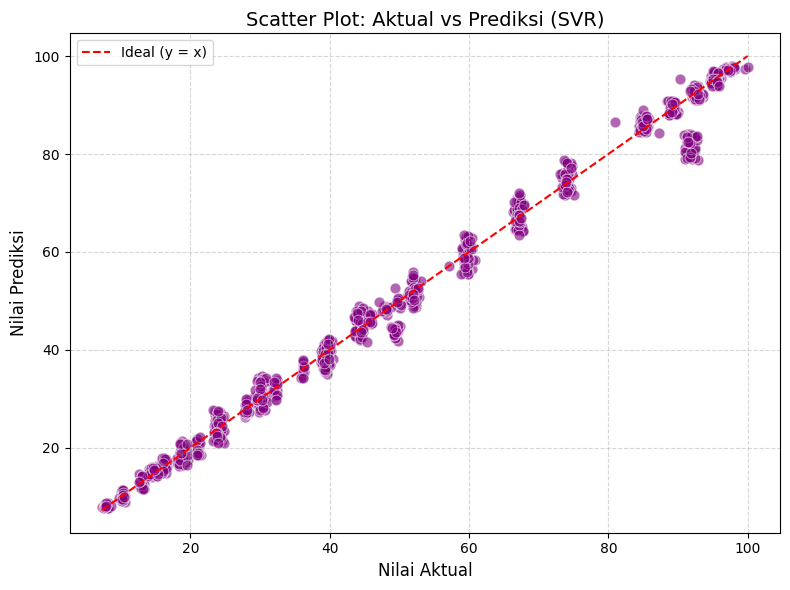

In [ ]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. Inisialisasi model SVR dengan pipeline scaling
svr_model = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=100, epsilon=0.1))

# 2. Training model SVR
svr_model.fit(X_train, y_train)

# 3. Prediksi dan evaluasi
svr_pred = svr_model.predict(X_test)
svr_mse = mean_squared_error(y_test, svr_pred)
svr_r2 = r2_score(y_test, svr_pred)

print("\n=== Support Vector Regression (SVR) ===")
print(f"📊 Mean Squared Error (MSE): {svr_mse:.2f}")
print(f"📈 R² Score: {svr_r2:.5f}")

# 4. Visualisasi scatter plot: Aktual vs Prediksi
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=svr_pred, color='purple', alpha=0.6, s=60)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Ideal (y = x)")
plt.xlabel("Nilai Aktual", fontsize=12)
plt.ylabel("Nilai Prediksi", fontsize=12)
plt.title("Scatter Plot: Aktual vs Prediksi (SVR)", fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:
# --- ✅ Cek Statistik Awal ---
print(f"Jumlah transaksi (CustomerMonth): {len(df_encoded)}")
print(f"Jumlah produk unik: {df_encoded.shape[1]}")
print(f"Rata-rata item per transaksi: {df_encoded.sum(axis=1).mean():.2f}")

In [ ]:
!pip install lightgbm

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001786 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1736
[LightGBM] [Info] Number of data points in the train set: 4500, number of used features: 9
[LightGBM] [Info] Start training from score 51.687247
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best g

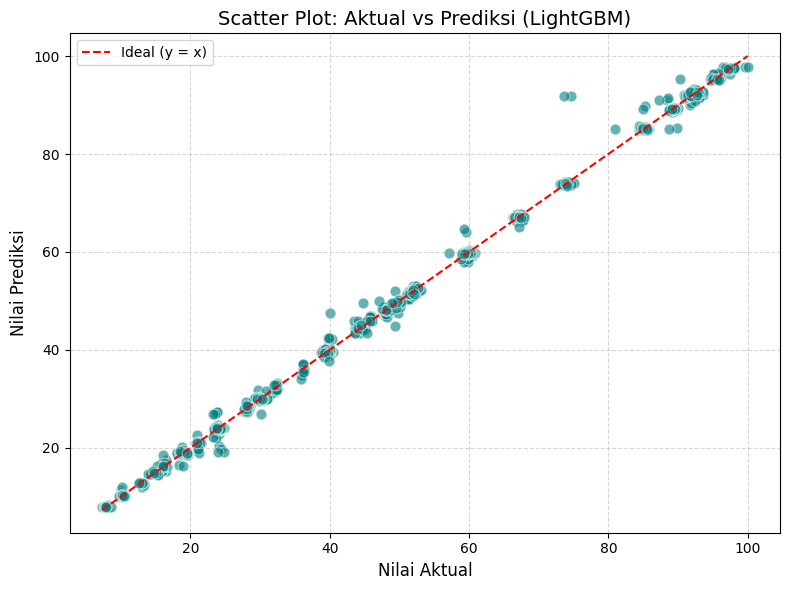

In [ ]:
from lightgbm import LGBMRegressor

# 1. Inisialisasi dan pelatihan model LightGBM
lgbm_model = LGBMRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
lgbm_model.fit(X_train, y_train)

# 2. Prediksi dan evaluasi model
lgbm_pred = lgbm_model.predict(X_test)
lgbm_mse = mean_squared_error(y_test, lgbm_pred)
lgbm_r2 = r2_score(y_test, lgbm_pred)

print("\n=== LightGBM Regressor ===")
print(f"📊 Mean Squared Error (MSE): {lgbm_mse:.2f}")
print(f"📈 R² Score: {lgbm_r2:.5f}")

# 3. Visualisasi scatter plot: Aktual vs Prediksi
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=lgbm_pred, color='teal', alpha=0.6, s=60)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Ideal (y = x)")
plt.xlabel("Nilai Aktual", fontsize=12)
plt.ylabel("Nilai Prediksi", fontsize=12)
plt.title("Scatter Plot: Aktual vs Prediksi (LightGBM)", fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.linear_model import LinearRegression

# Inisialisasi dan pelatihan model
linreg_model = LinearRegression()
linreg_model.fit(X_train, y_train)

# Prediksi dan evaluasi
linreg_pred = linreg_model.predict(X_test)
linreg_mse = mean_squared_error(y_test, linreg_pred)
linreg_r2 = r2_score(y_test, linreg_pred)

print("\n=== Linear Regression ===")
print(f"📊 MSE: {linreg_mse:.2f}")
print(f"📈 R²: {linreg_r2:.5f}")


=== Linear Regression ===
📊 MSE: 19.34
📈 R²: 0.97594


In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 3.7 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostRegressor

# Inisialisasi dan pelatihan
cat_model = CatBoostRegressor(verbose=0, random_state=42)
cat_model.fit(X_train, y_train)

# Prediksi dan evaluasi
cat_pred = cat_model.predict(X_test)
cat_mse = mean_squared_error(y_test, cat_pred)
cat_r2 = r2_score(y_test, cat_pred)

print("\n=== CatBoost Regressor ===")
print(f"📊 MSE: {cat_mse:.2f}")
print(f"📈 R²: {cat_r2:.5f}")



=== CatBoost Regressor ===
📊 MSE: 1.43
📈 R²: 0.99822


In [ ]:
from sklearn.linear_model import Ridge, Lasso

# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_r2 = r2_score(y_test, ridge_pred)

print("\n=== Ridge Regression ===")
print(f"📊 MSE: {ridge_mse:.2f}")
print(f"📈 R²: {ridge_r2:.5f}")

# Lasso Regression
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)
lasso_mse = mean_squared_error(y_test, lasso_pred)
lasso_r2 = r2_score(y_test, lasso_pred)

print("\n=== Lasso Regression ===")
print(f"📊 MSE: {lasso_mse:.2f}")
print(f"📈 R²: {lasso_r2:.5f}")



=== Ridge Regression ===
📊 MSE: 19.38
📈 R²: 0.97590

=== Lasso Regression ===
📊 MSE: 19.35
📈 R²: 0.97593
